In [1]:
from collections import defaultdict
from pathlib import Path

import matplotlib as mpl
import numpy as np
from matplotlib import patheffects as mpe
from matplotlib import pyplot as plt
from matplotlib import ticker as mtick
from numpy import array, float32, inf, nan  # noqa: F401

In [2]:
plots = Path("plots") / "quantiles"

In [3]:
from dataclasses import dataclass
from enum import StrEnum


@dataclass
class BitInformationBounds:
    percentile: list[float]
    keepbits: list[int]
    linquant_absolute: list[float]
    bitround_relative: list[float]


class ErrorKind(StrEnum):
    POINTWISE = "pointwise"
    MEAN = "mean"

    def __repr__(self) -> str:
        return f"{type(self).__name__}.{self._name_}"


@dataclass
class ExpertEnsembleSpreadQuantile:
    absolute: float
    absolute_value: float
    absolute_kind: ErrorKind
    relative: float
    relative_value: float
    relative_kind: ErrorKind


@dataclass
class EnsembleSpreadBounds:
    percentile: list[float]
    absolute: list[float]
    relative: list[float]
    quadratic: list[float]


@dataclass
class RangeBounds:
    min: float
    max: float
    min_abs: float

In [4]:
def parse_single(path: Path):
    with Path(path).open() as f:
        for line in f:
            var, rest = line.split(": ", 1)
            info = eval(rest)

            yield var, info

In [5]:
def parse_pressure(path: Path):
    with Path(path).open() as f:
        ls = iter(f.readlines())

        line = None

        while True:
            if line is None:
                try:
                    line = next(ls)
                except StopIteration:
                    break

            var, rest = line.split(":", 1)

            while True:
                try:
                    line = next(ls)
                except StopIteration:
                    line = None
                    break

                if len(line.strip()) == 0:
                    continue

                if not line.startswith(" - "):
                    break

                level, rest = line[len(" - ") :].split(": ", 1)
                info = eval(rest)

                yield var, level, info

In [6]:
single_expert = list(parse_single("expert-quantile-single.txt"))

In [7]:
pressure_expert = list(parse_pressure("expert-quantile-pressure.txt"))

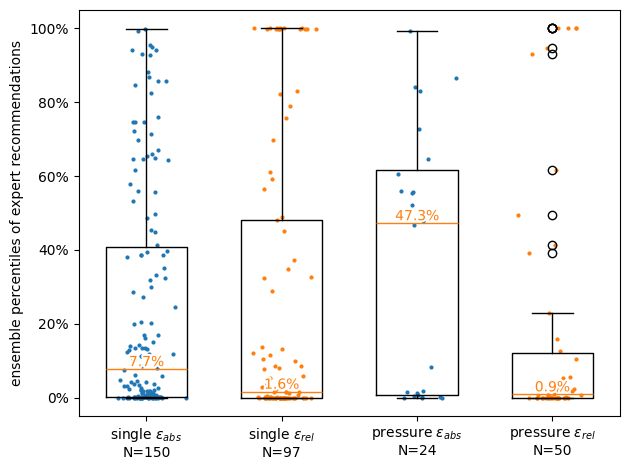

In [8]:
fig, ax = plt.subplots()

rng = np.random.default_rng(seed=42)

sabs = [1 - q.absolute for v, q in single_expert if not np.isnan(q.absolute)]
srel = [1 - q.relative for v, q in single_expert if not np.isnan(q.relative)]

b1 = ax.boxplot(sabs, positions=[0.0])
ax.scatter(rng.normal(loc=0.0, scale=0.025, size=len(sabs)), sabs, s=4, c="tab:blue")
ax.text(
    0.0,
    np.median(sabs),
    f"{np.format_float_positional(100 * np.median(sabs), precision=1, min_digits=1)}%",
    ha="center",
    va="bottom",
    color=b1["medians"][0].get_color(),
    path_effects=[mpe.withStroke(linewidth=3, foreground="white")],
)

b2 = ax.boxplot(srel, positions=[0.25])
ax.scatter(rng.normal(loc=0.25, scale=0.025, size=len(srel)), srel, s=4, c="tab:orange")
ax.text(
    0.25,
    np.median(srel),
    f"{np.format_float_positional(100 * np.median(srel), precision=1, min_digits=1)}%",
    ha="center",
    va="bottom",
    color=b2["medians"][0].get_color(),
    path_effects=[mpe.withStroke(linewidth=3, foreground="white")],
)

pabs = [1 - q.absolute for v, p, q in pressure_expert if not np.isnan(q.absolute)]
prel = [1 - q.relative for v, p, q in pressure_expert if not np.isnan(q.relative)]

b3 = ax.boxplot(pabs, positions=[0.5])
ax.scatter(rng.normal(loc=0.5, scale=0.025, size=len(pabs)), pabs, s=4, c="tab:blue")
ax.text(
    0.5,
    np.median(pabs),
    f"{np.format_float_positional(100 * np.median(pabs), precision=1, min_digits=1)}%",
    ha="center",
    va="bottom",
    color=b3["medians"][0].get_color(),
    path_effects=[mpe.withStroke(linewidth=3, foreground="white")],
)

b4 = ax.boxplot(prel, positions=[0.75])
ax.scatter(rng.normal(loc=0.75, scale=0.025, size=len(prel)), prel, s=4, c="tab:orange")
ax.text(
    0.75,
    np.median(prel),
    f"{np.format_float_positional(100 * np.median(prel), precision=1, min_digits=1)}%",
    ha="center",
    va="bottom",
    color=b4["medians"][0].get_color(),
    path_effects=[mpe.withStroke(linewidth=3, foreground="white")],
)

ax.set_xticks([0.0, 0.25, 0.5, 0.75])
ax.set_xticklabels(
    [
        f"single $\\epsilon_{{abs}}$\nN={len(sabs)}",
        f"single $\\epsilon_{{rel}}$\nN={len(srel)}",
        f"pressure $\\epsilon_{{abs}}$\nN={len(pabs)}",
        f"pressure $\\epsilon_{{rel}}$\nN={len(prel)}",
    ]
)
ax.set_xlim(-0.125, 0.875)
ax.set_ylabel("ensemble percentiles of expert recommendations")
ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0))

plt.tight_layout()

plt.show()
fig.savefig(plots / "boxplot.pdf")

In [9]:
single_range = dict(parse_single("range-single.txt"))

In [10]:
single_bit_information = dict(parse_single("bit-information-single.txt"))

In [11]:
from compression_recommendations import Recommendations
from compression_recommendations.requirements.error_bounds.max import (
    MaxPointwiseAbsoluteErrorBoundRequirement,
    MaxPointwiseQuadraticErrorBoundRequirement,
    MaxPointwiseRangeRelativeErrorBoundRequirement,
    MaxPointwiseRelativeErrorBoundRequirement,
)

In [12]:
with Path("recommendations", "grib-linear-packing.yaml").open("r") as f:
    grib_recommendations = Recommendations.load(f)

In [13]:
single_grib = dict()
for key in single_bit_information:
    (requirement,) = grib_recommendations.search(
        markers={"cf-short-name": key, "level-kind": "single"}
    )
    assert isinstance(requirement, MaxPointwiseRangeRelativeErrorBoundRequirement)
    single_grib[key] = requirement.value

In [14]:
with Path("recommendations", "ensemble-spread.yaml").open("r") as f:
    ensemble_recommendations = Recommendations.load(f)

In [15]:
single_ensemble = dict()
for key in single_bit_information:
    percentile = [1.0, 0.999, 0.99, 0.95]
    absolute = []
    for p in percentile:
        (requirement,) = ensemble_recommendations.search(
            markers={
                "cf-short-name": key,
                "level-kind": "single",
                "tags": f"absolute,{p * 100}%",
            }
        )
        assert isinstance(requirement, MaxPointwiseAbsoluteErrorBoundRequirement), repr(
            requirement
        )
        absolute.append(requirement.value)
    relative = []
    for p in percentile:
        (requirement,) = ensemble_recommendations.search(
            markers={
                "cf-short-name": key,
                "level-kind": "single",
                "tags": f"relative,{p * 100}%",
            }
        )
        assert isinstance(requirement, MaxPointwiseRelativeErrorBoundRequirement), repr(
            requirement
        )
        relative.append(requirement.value)
    quadratic = []
    for p in percentile:
        (requirement,) = ensemble_recommendations.search(
            markers={
                "cf-short-name": key,
                "level-kind": "single",
                "tags": f"quadratic,{p * 100}%",
            }
        )
        assert isinstance(requirement, MaxPointwiseQuadraticErrorBoundRequirement), (
            repr(requirement)
        )
        quadratic.append(requirement.value)
    single_ensemble[key] = EnsembleSpreadBounds(
        percentile=percentile, absolute=absolute, relative=relative, quadratic=quadratic
    )

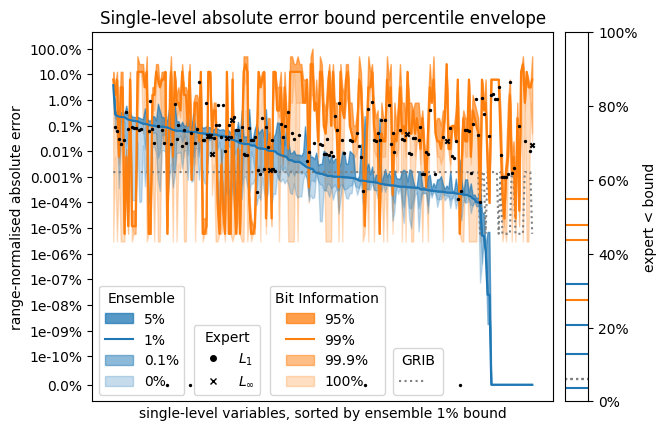

In [16]:
fig, (ax, axr) = plt.subplots(1, 2, width_ratios=[20, 1], gridspec_kw=dict(wspace=0.05))

ax.set_title("Single-level absolute error bound percentile envelope")
ax.set_ylabel("range-normalised absolute error")

scores = {
    v: (
        0.0
        if single_range[v].max == single_range[v].min
        else (e.absolute[2] / (single_range[v].max - single_range[v].min))
    )
    for v, e in single_ensemble.items()
}
v_sorted = sorted(scores.keys(), key=lambda k: scores[k], reverse=True)

ax.plot(
    [single_grib[v] for v in v_sorted],
    color="gray",
    ls=":",
)

single_expert_dict = dict(single_expert)
expert_xs = []
expert_ys = []
expert_pointwise = []
for i, v in enumerate(v_sorted):
    expert_xs.append(i)
    expert_ys.append(
        0.0
        if single_range[v].max == single_range[v].min
        else (
            single_expert_dict[v].absolute_value
            / (single_range[v].max - single_range[v].min)
        )
    )
    expert_pointwise.append(single_expert_dict[v].absolute_kind is ErrorKind.POINTWISE)
expert_pointwise = np.array(expert_pointwise)
ax.scatter(
    np.array(expert_xs)[expert_pointwise],
    np.array(expert_ys)[expert_pointwise],
    s=10,
    marker="x",
    c="black",
    label="expert",
    zorder=9,
)
ax.scatter(
    np.array(expert_xs)[~expert_pointwise],
    np.array(expert_ys)[~expert_pointwise],
    s=2,
    marker="o",
    c="black",
    label="expert",
    zorder=9,
)

ax.fill_between(
    range(len(v_sorted)),
    [
        (
            0.0
            if single_range[v].max == single_range[v].min
            else (
                single_bit_information[v].linquant_absolute[0]
                / (single_range[v].max - single_range[v].min)
            )
        )
        for v in v_sorted
    ],
    [
        (
            0.0
            if single_range[v].max == single_range[v].min
            else (
                single_bit_information[v].linquant_absolute[2]
                / (single_range[v].max - single_range[v].min)
            )
        )
        for v in v_sorted
    ],
    alpha=0.25,
    color="tab:orange",
    label="100%",
)
ax.fill_between(
    range(len(v_sorted)),
    [
        (
            0.0
            if single_range[v].max == single_range[v].min
            else (
                single_bit_information[v].linquant_absolute[1]
                / (single_range[v].max - single_range[v].min)
            )
        )
        for v in v_sorted
    ],
    [
        (
            0.0
            if single_range[v].max == single_range[v].min
            else (
                single_bit_information[v].linquant_absolute[2]
                / (single_range[v].max - single_range[v].min)
            )
        )
        for v in v_sorted
    ],
    alpha=0.25,
    color="tab:orange",
    label="99.9%",
)
ax.plot(
    [
        (
            0.0
            if single_range[v].max == single_range[v].min
            else (
                single_bit_information[v].linquant_absolute[2]
                / (single_range[v].max - single_range[v].min)
            )
        )
        for v in v_sorted
    ],
    color="tab:orange",
    label="99%",
)
ax.fill_between(
    range(len(v_sorted)),
    [
        (
            0.0
            if single_range[v].max == single_range[v].min
            else (
                single_bit_information[v].linquant_absolute[3]
                / (single_range[v].max - single_range[v].min)
            )
        )
        for v in v_sorted
    ],
    [
        (
            0.0
            if single_range[v].max == single_range[v].min
            else (
                single_bit_information[v].linquant_absolute[2]
                / (single_range[v].max - single_range[v].min)
            )
        )
        for v in v_sorted
    ],
    alpha=0.66,
    color="tab:orange",
    label="95%",
)

ax.fill_between(
    range(len(v_sorted)),
    [
        (
            0.0
            if single_range[v].max == single_range[v].min
            else (
                single_ensemble[v].absolute[0]
                / (single_range[v].max - single_range[v].min)
            )
        )
        for v in v_sorted
    ],
    [
        (
            0.0
            if single_range[v].max == single_range[v].min
            else (
                single_ensemble[v].absolute[2]
                / (single_range[v].max - single_range[v].min)
            )
        )
        for v in v_sorted
    ],
    alpha=0.25,
    color="tab:blue",
    label="0%",
)
ax.fill_between(
    range(len(v_sorted)),
    [
        (
            0.0
            if single_range[v].max == single_range[v].min
            else (
                single_ensemble[v].absolute[1]
                / (single_range[v].max - single_range[v].min)
            )
        )
        for v in v_sorted
    ],
    [
        (
            0.0
            if single_range[v].max == single_range[v].min
            else (
                single_ensemble[v].absolute[2]
                / (single_range[v].max - single_range[v].min)
            )
        )
        for v in v_sorted
    ],
    alpha=0.25,
    color="tab:blue",
    label="0.1%",
)
ax.plot(
    [
        (
            0.0
            if single_range[v].max == single_range[v].min
            else (
                single_ensemble[v].absolute[2]
                / (single_range[v].max - single_range[v].min)
            )
        )
        for v in v_sorted
    ],
    color="tab:blue",
    label="1%",
)
ax.fill_between(
    range(len(v_sorted)),
    [
        (
            0.0
            if single_range[v].max == single_range[v].min
            else (
                single_ensemble[v].absolute[3]
                / (single_range[v].max - single_range[v].min)
            )
        )
        for v in v_sorted
    ],
    [
        (
            0.0
            if single_range[v].max == single_range[v].min
            else (
                single_ensemble[v].absolute[2]
                / (single_range[v].max - single_range[v].min)
            )
        )
        for v in v_sorted
    ],
    alpha=0.66,
    color="tab:blue",
    label="5%",
)

ax.set_yscale("symlog", linthresh=1e-12)

l1 = ax.legend(
    handles=[
        mpl.patches.Patch(color="tab:blue", alpha=0.75, label="5%"),
        mpl.lines.Line2D([0], [0], color="tab:blue", label="1%"),
        mpl.patches.Patch(color="tab:blue", alpha=0.5, label="0.1%"),
        mpl.patches.Patch(color="tab:blue", alpha=0.25, label="0%"),
    ],
    ncol=1,
    loc="lower left",
    title="Ensemble",
)
l2 = ax.legend(
    handles=[
        mpl.lines.Line2D(
            [0],
            [0],
            markersize=4,
            marker="o",
            color="none",
            markerfacecolor="black",
            markeredgecolor="black",
            label="$L_1$",
        ),
        mpl.lines.Line2D(
            [0],
            [0],
            markersize=4,
            marker="x",
            color="none",
            markerfacecolor="black",
            markeredgecolor="black",
            label=r"$L_{\infty}$",
        ),
    ],
    ncol=1,
    loc="lower left",
    bbox_to_anchor=(0.205, 0, 1, 1),
    title="Expert",
)
l3 = ax.legend(
    handles=[
        mpl.patches.Patch(color="tab:orange", alpha=0.75, label="95%"),
        mpl.lines.Line2D([0], [0], color="tab:orange", label="99%"),
        mpl.patches.Patch(color="tab:orange", alpha=0.5, label="99.9%"),
        mpl.patches.Patch(color="tab:orange", alpha=0.25, label="100%"),
    ],
    ncol=1,
    loc="lower left",
    bbox_to_anchor=(0.37, 0, 1, 1),
    title="Bit Information",
)
ax.legend(
    handles=[
        mpl.lines.Line2D([0], [0], color="gray", ls=":"),
    ],
    ncol=1,
    loc="lower left",
    bbox_to_anchor=(0.6375, 0, 1, 1),
    title="GRIB",
)
ax.add_artist(l1)
ax.add_artist(l2)
ax.add_artist(l3)

ax.set_xticks([])
ax.set_xlabel("single-level variables, sorted by ensemble 1% bound")
ax.yaxis.set_major_formatter(
    mtick.FuncFormatter(
        lambda x, pos=None: (
            f"{np.round(x * 100, 10)}%"
            if x == 0 or x >= 1e-5
            else f"{np.round(x * 100, 10):.0e}%"
        )
    )
)

axr.set_xticks([])
axr.yaxis.tick_right()
axr.yaxis.set_label_position("right")
axr.set_ylabel("expert < bound")
axr.yaxis.set_major_formatter(mtick.PercentFormatter(1))
axr.set_ylim(0, 1)

for i, p in enumerate(single_ensemble["u10"].percentile):
    count = 0
    for v in single_expert_dict:
        count += single_expert_dict[v].absolute_value < single_ensemble[v].absolute[i]
    axr.axhline(count / len(single_expert_dict), c="tab:blue")

for i, p in enumerate(single_ensemble["u10"].percentile):
    count = 0
    for v in single_expert_dict:
        count += (
            single_expert_dict[v].absolute_value
            < single_bit_information[v].linquant_absolute[i]
        )
    axr.axhline(count / len(single_expert_dict), c="tab:orange")

for i, p in enumerate(single_ensemble["u10"].percentile):
    count = 0
    for v in single_expert_dict:
        count += single_expert_dict[v].absolute_value < (
            single_grib[v] * (single_range[v].max - single_range[v].min)
        )
    axr.axhline(count / len(single_expert_dict), c="gray", ls=":")

plt.show()
fig.savefig(plots / "single-absolute.pdf")

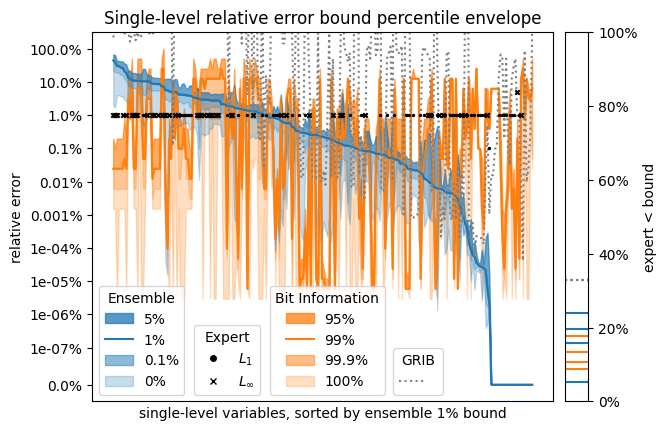

In [17]:
fig, (ax, axr) = plt.subplots(1, 2, width_ratios=[20, 1], gridspec_kw=dict(wspace=0.05))

ax.set_title("Single-level relative error bound percentile envelope")
ax.set_ylabel("relative error")

scores = {v: e.relative[2] for v, e in single_ensemble.items()}
v_sorted = sorted(scores.keys(), key=lambda k: scores[k], reverse=True)

single_expert_dict = dict(single_expert)
expert_xs = []
expert_ys = []
expert_pointwise = []
for i, v in enumerate(v_sorted):
    expert_xs.append(i)
    expert_ys.append(single_expert_dict[v].relative_value)
    expert_pointwise.append(single_expert_dict[v].absolute_kind is ErrorKind.POINTWISE)
expert_pointwise = np.array(expert_pointwise)
ax.scatter(
    np.array(expert_xs)[expert_pointwise],
    np.array(expert_ys)[expert_pointwise],
    s=10,
    marker="x",
    c="black",
    label="expert",
    zorder=9,
)
ax.scatter(
    np.array(expert_xs)[~expert_pointwise],
    np.array(expert_ys)[~expert_pointwise],
    s=2,
    marker="o",
    c="black",
    label="expert",
    zorder=9,
)

ax.fill_between(
    range(len(v_sorted)),
    [single_bit_information[v].bitround_relative[0] for v in v_sorted],
    [single_bit_information[v].bitround_relative[2] for v in v_sorted],
    alpha=0.25,
    color="tab:orange",
    label="100%",
)
ax.fill_between(
    range(len(v_sorted)),
    [single_bit_information[v].bitround_relative[1] for v in v_sorted],
    [single_bit_information[v].bitround_relative[2] for v in v_sorted],
    alpha=0.25,
    color="tab:orange",
    label="99.9%",
)
ax.plot(
    [single_bit_information[v].bitround_relative[2] for v in v_sorted],
    color="tab:orange",
    label="99%",
)
ax.fill_between(
    range(len(v_sorted)),
    [single_bit_information[v].bitround_relative[3] for v in v_sorted],
    [single_bit_information[v].bitround_relative[2] for v in v_sorted],
    alpha=0.66,
    color="tab:orange",
    label="95%",
)

ax.fill_between(
    range(len(v_sorted)),
    [single_ensemble[v].relative[0] for v in v_sorted],
    [single_ensemble[v].relative[2] for v in v_sorted],
    alpha=0.25,
    color="tab:blue",
    label="0%",
)
ax.fill_between(
    range(len(v_sorted)),
    [single_ensemble[v].relative[1] for v in v_sorted],
    [single_ensemble[v].relative[2] for v in v_sorted],
    alpha=0.25,
    color="tab:blue",
    label="0.1%",
)
ax.plot(
    [single_ensemble[v].relative[2] for v in v_sorted], color="tab:blue", label="1%"
)
ax.fill_between(
    range(len(v_sorted)),
    [single_ensemble[v].relative[3] for v in v_sorted],
    [single_ensemble[v].relative[2] for v in v_sorted],
    alpha=0.66,
    color="tab:blue",
    label="5%",
)

ax.set_yscale("symlog", linthresh=1e-9)

ylim = ax.get_ylim()

ax.plot(
    [
        single_grib[v]
        * (single_range[v].max - single_range[v].min)
        / single_range[v].min_abs
        for v in v_sorted
    ],
    color="gray",
    ls=":",
)

ax.set_ylim(*ylim)

l1 = ax.legend(
    handles=[
        mpl.patches.Patch(color="tab:blue", alpha=0.75, label="5%"),
        mpl.lines.Line2D([0], [0], color="tab:blue", label="1%"),
        mpl.patches.Patch(color="tab:blue", alpha=0.5, label="0.1%"),
        mpl.patches.Patch(color="tab:blue", alpha=0.25, label="0%"),
    ],
    ncol=1,
    loc="lower left",
    title="Ensemble",
)
l2 = ax.legend(
    handles=[
        mpl.lines.Line2D(
            [0],
            [0],
            markersize=4,
            marker="o",
            color="none",
            markerfacecolor="black",
            markeredgecolor="black",
            label="$L_1$",
        ),
        mpl.lines.Line2D(
            [0],
            [0],
            markersize=4,
            marker="x",
            color="none",
            markerfacecolor="black",
            markeredgecolor="black",
            label=r"$L_{\infty}$",
        ),
    ],
    ncol=1,
    loc="lower left",
    bbox_to_anchor=(0.205, 0, 1, 1),
    title="Expert",
)
l3 = ax.legend(
    handles=[
        mpl.patches.Patch(color="tab:orange", alpha=0.75, label="95%"),
        mpl.lines.Line2D([0], [0], color="tab:orange", label="99%"),
        mpl.patches.Patch(color="tab:orange", alpha=0.5, label="99.9%"),
        mpl.patches.Patch(color="tab:orange", alpha=0.25, label="100%"),
    ],
    ncol=1,
    loc="lower left",
    bbox_to_anchor=(0.37, 0, 1, 1),
    title="Bit Information",
)
ax.legend(
    handles=[
        mpl.lines.Line2D([0], [0], color="gray", ls=":"),
    ],
    ncol=1,
    loc="lower left",
    bbox_to_anchor=(0.6375, 0, 1, 1),
    title="GRIB",
)
ax.add_artist(l1)
ax.add_artist(l2)
ax.add_artist(l3)

ax.set_xticks([])
ax.set_xlabel("single-level variables, sorted by ensemble 1% bound")
ax.yaxis.set_major_formatter(
    mtick.FuncFormatter(
        lambda x, pos=None: (
            f"{np.round(x * 100, 7)}%"
            if x == 0 or x >= 1e-5
            else f"{np.round(x * 100, 7):.0e}%"
        )
    )
)

axr.set_xticks([])
axr.yaxis.tick_right()
axr.yaxis.set_label_position("right")
axr.set_ylabel("expert < bound")
axr.yaxis.set_major_formatter(mtick.PercentFormatter(1))
axr.set_ylim(0, 1)

for i, p in enumerate(single_ensemble["u10"].percentile):
    count = 0
    for v in single_expert_dict:
        count += single_expert_dict[v].relative_value < single_ensemble[v].relative[i]
    axr.axhline(count / len(single_expert_dict), c="tab:blue")

for i, p in enumerate(single_ensemble["u10"].percentile):
    count = 0
    for v in single_expert_dict:
        count += (
            single_expert_dict[v].relative_value
            < single_bit_information[v].bitround_relative[i]
        )
    axr.axhline(count / len(single_expert_dict), c="tab:orange")

for i, p in enumerate(single_ensemble["u10"].percentile):
    count = 0
    for v in single_expert_dict:
        count += single_expert_dict[v].relative_value < (
            single_grib[v]
            * (single_range[v].max - single_range[v].min)
            / single_range[v].min_abs
        )
    axr.axhline(count / len(single_expert_dict), c="gray", ls=":")

plt.show()
fig.savefig(plots / "single-relative.pdf")

In [18]:
pressure_bit_information = defaultdict(dict)
for v, p, r in parse_pressure("bit-information-pressure.txt"):
    pressure_bit_information[p][v] = r

In [19]:
pressure_range = defaultdict(dict)
for v, p, r in parse_pressure("range-pressure.txt"):
    pressure_range[p][v] = r

In [20]:
pressure_grib = dict()
for pressure in pressure_bit_information:
    pressure_grib[pressure] = dict()
    for key in pressure_bit_information[pressure]:
        (requirement,) = grib_recommendations.search(
            markers={
                "cf-short-name": key,
                "level-kind": "pressure",
                "level-value": float(pressure.split(" ")[0]),
            }
        )
        assert isinstance(requirement, MaxPointwiseRangeRelativeErrorBoundRequirement)
        pressure_grib[pressure][key] = requirement.value

In [21]:
pressure_ensemble = dict()
for pressure in pressure_bit_information:
    pressure_ensemble[pressure] = dict()
    for key in pressure_bit_information[pressure]:
        percentile = [1.0, 0.999, 0.99, 0.95]
        absolute = []
        for p in percentile:
            (requirement,) = ensemble_recommendations.search(
                markers={
                    "cf-short-name": key,
                    "level-kind": "pressure",
                    "level-value": float(pressure.split(" ")[0]),
                    "tags": f"absolute,{p * 100}%",
                }
            )
            assert isinstance(requirement, MaxPointwiseAbsoluteErrorBoundRequirement), (
                repr(requirement)
            )
            absolute.append(requirement.value)
        relative = []
        for p in percentile:
            (requirement,) = ensemble_recommendations.search(
                markers={
                    "cf-short-name": key,
                    "level-kind": "pressure",
                    "level-value": float(pressure.split(" ")[0]),
                    "tags": f"relative,{p * 100}%",
                }
            )
            assert isinstance(requirement, MaxPointwiseRelativeErrorBoundRequirement), (
                repr(requirement)
            )
            relative.append(requirement.value)
        quadratic = []
        for p in percentile:
            (requirement,) = ensemble_recommendations.search(
                markers={
                    "cf-short-name": key,
                    "level-kind": "pressure",
                    "level-value": float(pressure.split(" ")[0]),
                    "tags": f"quadratic,{p * 100}%",
                }
            )
            assert isinstance(
                requirement, MaxPointwiseQuadraticErrorBoundRequirement
            ), repr(requirement)
            quadratic.append(requirement.value)
        pressure_ensemble[pressure][key] = EnsembleSpreadBounds(
            percentile=percentile,
            absolute=absolute,
            relative=relative,
            quadratic=quadratic,
        )

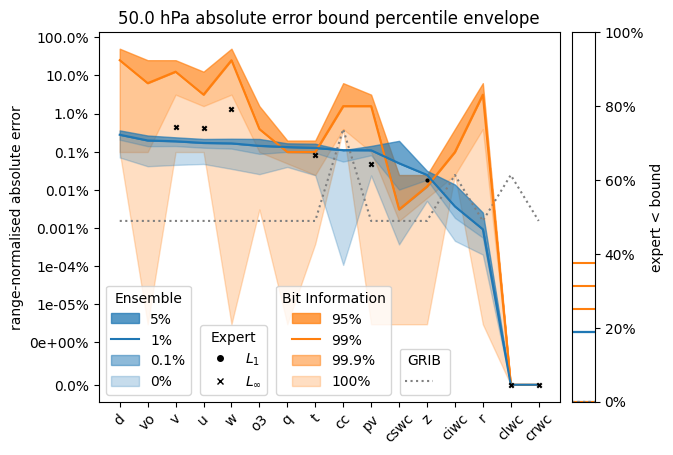

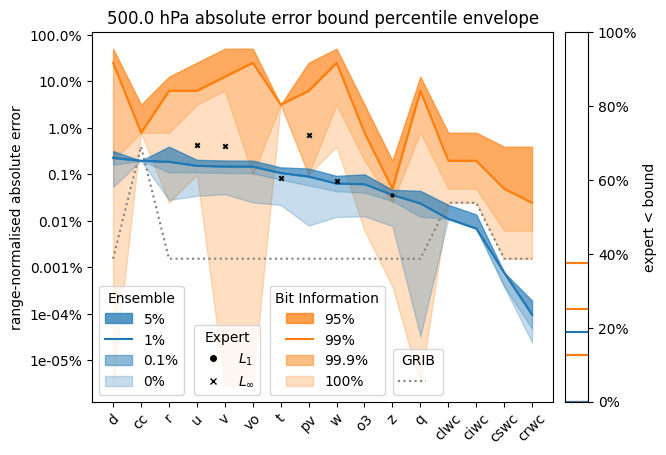

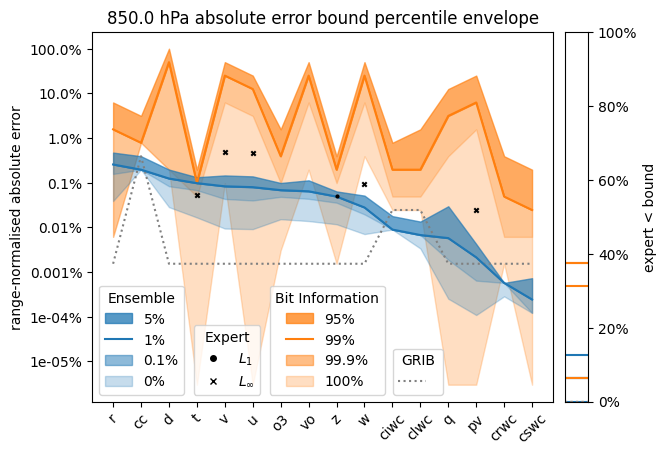

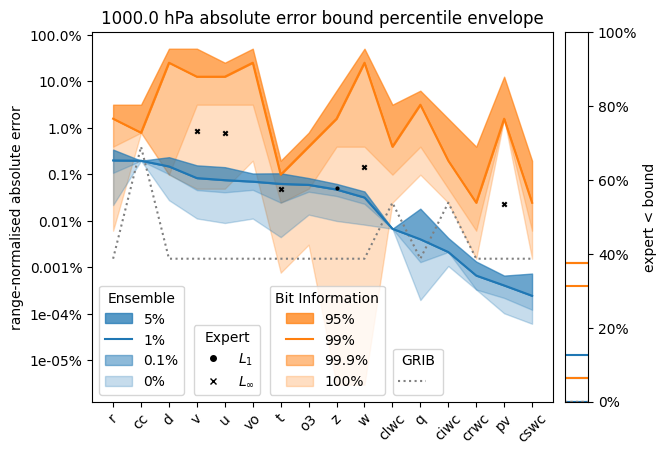

In [22]:
for p in pressure_ensemble:
    fig, (ax, axr) = plt.subplots(
        1, 2, width_ratios=[20, 1], gridspec_kw=dict(wspace=0.05)
    )

    ax.set_title(f"{p} absolute error bound percentile envelope")
    ax.set_ylabel("range-normalised absolute error")

    scores = {
        v: (
            0.0
            if pressure_range[p][v].max == pressure_range[p][v].min
            else (e.absolute[2] / (pressure_range[p][v].max - pressure_range[p][v].min))
        )
        for v, e in pressure_ensemble[p].items()
    }
    v_sorted = sorted(scores.keys(), key=lambda k: scores[k], reverse=True)

    ax.plot(
        [pressure_grib[p][v] for v in v_sorted],
        color="gray",
        ls=":",
    )

    pressure_expert_dict = defaultdict(dict)
    for v, p2, r in pressure_expert:
        pressure_expert_dict[p2][v] = r
    expert_xs = []
    expert_ys = []
    expert_pointwise = []
    for i, v in enumerate(v_sorted):
        expert_xs.append(i)
        expert_ys.append(
            0.0
            if pressure_range[p][v].max == pressure_range[p][v].min
            else (
                pressure_expert_dict[p][v].absolute_value
                / (pressure_range[p][v].max - pressure_range[p][v].min)
            )
        )
        expert_pointwise.append(
            pressure_expert_dict[p][v].absolute_kind is ErrorKind.POINTWISE
        )
    expert_pointwise = np.array(expert_pointwise)
    ax.scatter(
        np.array(expert_xs)[expert_pointwise],
        np.array(expert_ys)[expert_pointwise],
        s=10,
        marker="x",
        c="black",
        label="expert",
        zorder=9,
    )
    ax.scatter(
        np.array(expert_xs)[~expert_pointwise],
        np.array(expert_ys)[~expert_pointwise],
        s=4,
        marker="o",
        c="black",
        label="expert",
        zorder=9,
    )

    ax.fill_between(
        range(len(v_sorted)),
        [
            (
                0.0
                if pressure_range[p][v].max == pressure_range[p][v].min
                else (
                    pressure_bit_information[p][v].linquant_absolute[0]
                    / (pressure_range[p][v].max - pressure_range[p][v].min)
                )
            )
            for v in v_sorted
        ],
        [
            (
                0.0
                if pressure_range[p][v].max == pressure_range[p][v].min
                else (
                    pressure_bit_information[p][v].linquant_absolute[2]
                    / (pressure_range[p][v].max - pressure_range[p][v].min)
                )
            )
            for v in v_sorted
        ],
        alpha=0.25,
        color="tab:orange",
        label="100%",
    )
    ax.fill_between(
        range(len(v_sorted)),
        [
            (
                0.0
                if pressure_range[p][v].max == pressure_range[p][v].min
                else (
                    pressure_bit_information[p][v].linquant_absolute[1]
                    / (pressure_range[p][v].max - pressure_range[p][v].min)
                )
            )
            for v in v_sorted
        ],
        [
            (
                0.0
                if pressure_range[p][v].max == pressure_range[p][v].min
                else (
                    pressure_bit_information[p][v].linquant_absolute[2]
                    / (pressure_range[p][v].max - pressure_range[p][v].min)
                )
            )
            for v in v_sorted
        ],
        alpha=0.25,
        color="tab:orange",
        label="99.9%",
    )
    ax.plot(
        [
            (
                0.0
                if pressure_range[p][v].max == pressure_range[p][v].min
                else (
                    pressure_bit_information[p][v].linquant_absolute[2]
                    / (pressure_range[p][v].max - pressure_range[p][v].min)
                )
            )
            for v in v_sorted
        ],
        color="tab:orange",
        label="99%",
    )
    ax.fill_between(
        range(len(v_sorted)),
        [
            (
                0.0
                if pressure_range[p][v].max == pressure_range[p][v].min
                else (
                    pressure_bit_information[p][v].linquant_absolute[3]
                    / (pressure_range[p][v].max - pressure_range[p][v].min)
                )
            )
            for v in v_sorted
        ],
        [
            (
                0.0
                if pressure_range[p][v].max == pressure_range[p][v].min
                else (
                    pressure_bit_information[p][v].linquant_absolute[2]
                    / (pressure_range[p][v].max - pressure_range[p][v].min)
                )
            )
            for v in v_sorted
        ],
        alpha=0.66,
        color="tab:orange",
        label="95%",
    )

    ax.fill_between(
        range(len(v_sorted)),
        [
            (
                0.0
                if pressure_range[p][v].max == pressure_range[p][v].min
                else (
                    pressure_ensemble[p][v].absolute[0]
                    / (pressure_range[p][v].max - pressure_range[p][v].min)
                )
            )
            for v in v_sorted
        ],
        [
            (
                0.0
                if pressure_range[p][v].max == pressure_range[p][v].min
                else (
                    pressure_ensemble[p][v].absolute[2]
                    / (pressure_range[p][v].max - pressure_range[p][v].min)
                )
            )
            for v in v_sorted
        ],
        alpha=0.25,
        color="tab:blue",
        label="0%",
    )
    ax.fill_between(
        range(len(v_sorted)),
        [
            (
                0.0
                if pressure_range[p][v].max == pressure_range[p][v].min
                else (
                    pressure_ensemble[p][v].absolute[1]
                    / (pressure_range[p][v].max - pressure_range[p][v].min)
                )
            )
            for v in v_sorted
        ],
        [
            (
                0.0
                if pressure_range[p][v].max == pressure_range[p][v].min
                else (
                    pressure_ensemble[p][v].absolute[2]
                    / (pressure_range[p][v].max - pressure_range[p][v].min)
                )
            )
            for v in v_sorted
        ],
        alpha=0.25,
        color="tab:blue",
        label="0.1%",
    )
    ax.plot(
        [
            (
                0.0
                if pressure_range[p][v].max == pressure_range[p][v].min
                else (
                    pressure_ensemble[p][v].absolute[2]
                    / (pressure_range[p][v].max - pressure_range[p][v].min)
                )
            )
            for v in v_sorted
        ],
        color="tab:blue",
        label="1%",
    )
    ax.fill_between(
        range(len(v_sorted)),
        [
            (
                0.0
                if pressure_range[p][v].max == pressure_range[p][v].min
                else (
                    pressure_ensemble[p][v].absolute[3]
                    / (pressure_range[p][v].max - pressure_range[p][v].min)
                )
            )
            for v in v_sorted
        ],
        [
            (
                0.0
                if pressure_range[p][v].max == pressure_range[p][v].min
                else (
                    pressure_ensemble[p][v].absolute[2]
                    / (pressure_range[p][v].max - pressure_range[p][v].min)
                )
            )
            for v in v_sorted
        ],
        alpha=0.66,
        color="tab:blue",
        label="5%",
    )

    ax.set_yscale("symlog", linthresh=1e-8)

    l1 = ax.legend(
        handles=[
            mpl.patches.Patch(color="tab:blue", alpha=0.75, label="5%"),
            mpl.lines.Line2D([0], [0], color="tab:blue", label="1%"),
            mpl.patches.Patch(color="tab:blue", alpha=0.5, label="0.1%"),
            mpl.patches.Patch(color="tab:blue", alpha=0.25, label="0%"),
        ],
        ncol=1,
        loc="lower left",
        title="Ensemble",
    )
    l2 = ax.legend(
        handles=[
            mpl.lines.Line2D(
                [0],
                [0],
                markersize=4,
                marker="o",
                color="none",
                markerfacecolor="black",
                markeredgecolor="black",
                label="$L_1$",
            ),
            mpl.lines.Line2D(
                [0],
                [0],
                markersize=4,
                marker="x",
                color="none",
                markerfacecolor="black",
                markeredgecolor="black",
                label=r"$L_{\infty}$",
            ),
        ],
        ncol=1,
        loc="lower left",
        bbox_to_anchor=(0.205, 0, 1, 1),
        title="Expert",
    )
    l3 = ax.legend(
        handles=[
            mpl.patches.Patch(color="tab:orange", alpha=0.75, label="95%"),
            mpl.lines.Line2D([0], [0], color="tab:orange", label="99%"),
            mpl.patches.Patch(color="tab:orange", alpha=0.5, label="99.9%"),
            mpl.patches.Patch(color="tab:orange", alpha=0.25, label="100%"),
        ],
        ncol=1,
        loc="lower left",
        bbox_to_anchor=(0.37, 0, 1, 1),
        title="Bit Information",
    )
    ax.legend(
        handles=[
            mpl.lines.Line2D([0], [0], color="gray", ls=":"),
        ],
        ncol=1,
        loc="lower left",
        bbox_to_anchor=(0.6375, 0, 1, 1),
        title="GRIB",
    )
    ax.add_artist(l1)
    ax.add_artist(l2)
    ax.add_artist(l3)

    ax.set_xticks(range(len(v_sorted)))
    ax.set_xticklabels(v_sorted, rotation=45)
    # ax.set_xlabel("sorted by ensemble 1% bound")
    ax.yaxis.set_major_formatter(
        mtick.FuncFormatter(
            lambda x, pos=None: (
                f"{np.round(x * 100, 5)}%"
                if x == 0 or x >= 1e-5
                else f"{np.round(x * 100, 5):.0e}%"
            )
        )
    )

    axr.set_xticks([])
    axr.yaxis.tick_right()
    axr.yaxis.set_label_position("right")
    axr.set_ylabel("expert < bound")
    axr.yaxis.set_major_formatter(mtick.PercentFormatter(1))
    axr.set_ylim(0, 1)

    for i, pt in enumerate(pressure_ensemble["1000.0 hPa"]["u"].percentile):
        count = 0
        for v in pressure_expert_dict[p]:
            count += (
                pressure_expert_dict[p][v].absolute_value
                < pressure_ensemble[p][v].absolute[i]
            )
        axr.axhline(count / len(pressure_expert_dict[p]), c="tab:blue")

    for i, pt in enumerate(pressure_ensemble["1000.0 hPa"]["u"].percentile):
        count = 0
        for v in pressure_expert_dict[p]:
            count += (
                pressure_expert_dict[p][v].absolute_value
                < pressure_bit_information[p][v].linquant_absolute[i]
            )
        axr.axhline(count / len(pressure_expert_dict[p]), c="tab:orange")

    for i, pt in enumerate(pressure_ensemble["1000.0 hPa"]["u"].percentile):
        count = 0
        for v in pressure_expert_dict[p]:
            count += pressure_expert_dict[p][v].absolute_value < (
                pressure_grib[p][v]
                * (pressure_range[p][v].max - pressure_range[p][v].min)
            )
        axr.axhline(count / len(pressure_expert_dict[p]), c="gray", ls=":")

    plt.show()
    fig.savefig(plots / f"pressure-{p.replace(' ', '')}-absolute.pdf")

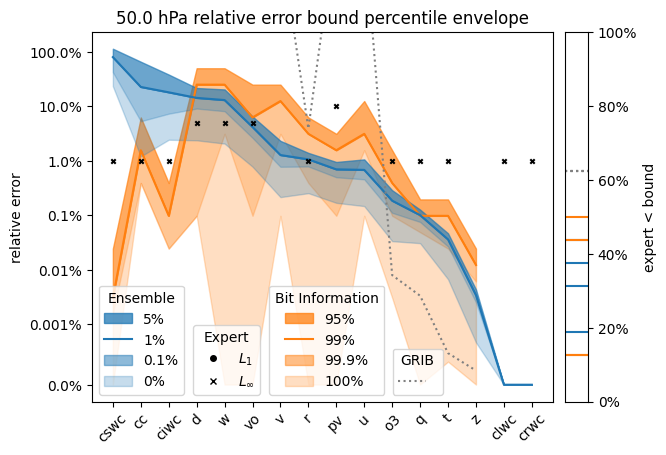

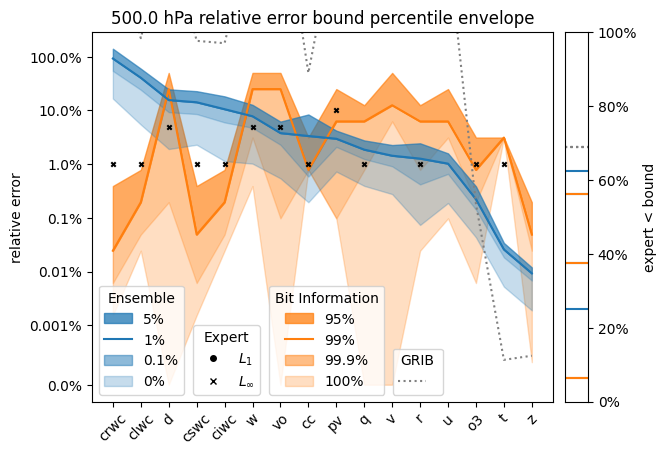

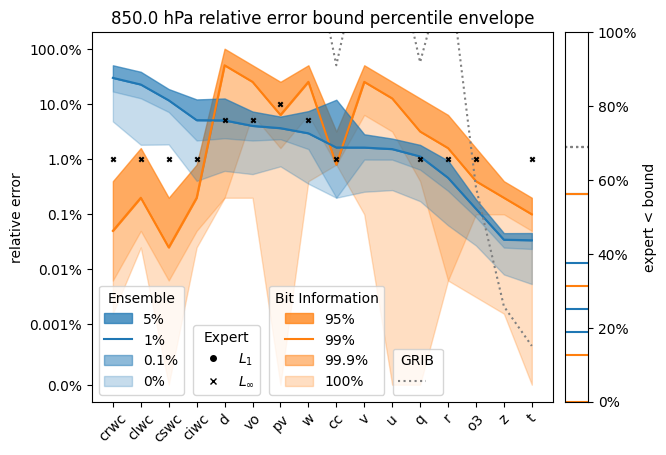

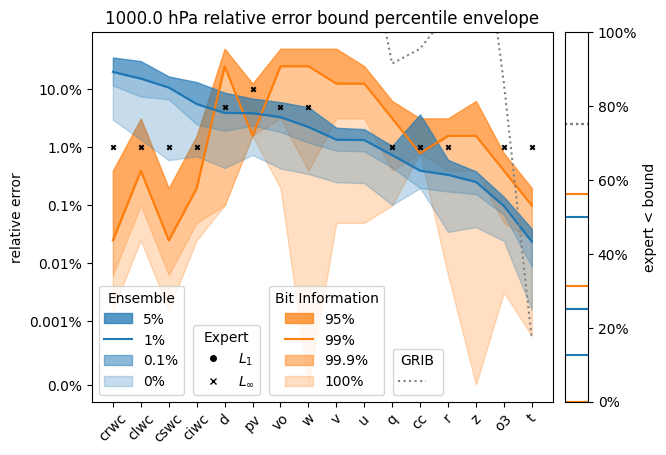

In [23]:
for p in pressure_ensemble:
    fig, (ax, axr) = plt.subplots(
        1, 2, width_ratios=[20, 1], gridspec_kw=dict(wspace=0.05)
    )

    ax.set_title(f"{p} relative error bound percentile envelope")
    ax.set_ylabel("relative error")

    scores = {v: e.relative[2] for v, e in pressure_ensemble[p].items()}
    v_sorted = sorted(scores.keys(), key=lambda k: scores[k], reverse=True)

    pressure_expert_dict = defaultdict(dict)
    for v, p2, r in pressure_expert:
        pressure_expert_dict[p2][v] = r
    expert_xs = []
    expert_ys = []
    expert_pointwise = []
    for i, v in enumerate(v_sorted):
        expert_xs.append(i)
        expert_ys.append(pressure_expert_dict[p][v].relative_value)
        expert_pointwise.append(
            pressure_expert_dict[p][v].absolute_kind is ErrorKind.POINTWISE
        )
    expert_pointwise = np.array(expert_pointwise)
    ax.scatter(
        np.array(expert_xs)[expert_pointwise],
        np.array(expert_ys)[expert_pointwise],
        s=10,
        marker="x",
        c="black",
        label="expert",
        zorder=9,
    )
    ax.scatter(
        np.array(expert_xs)[~expert_pointwise],
        np.array(expert_ys)[~expert_pointwise],
        s=4,
        marker="o",
        c="black",
        label="expert",
        zorder=9,
    )

    ax.fill_between(
        range(len(v_sorted)),
        [pressure_bit_information[p][v].bitround_relative[0] for v in v_sorted],
        [pressure_bit_information[p][v].bitround_relative[2] for v in v_sorted],
        alpha=0.25,
        color="tab:orange",
        label="100%",
    )
    ax.fill_between(
        range(len(v_sorted)),
        [pressure_bit_information[p][v].bitround_relative[1] for v in v_sorted],
        [pressure_bit_information[p][v].bitround_relative[2] for v in v_sorted],
        alpha=0.25,
        color="tab:orange",
        label="99.9%",
    )
    ax.plot(
        [pressure_bit_information[p][v].bitround_relative[2] for v in v_sorted],
        color="tab:orange",
        label="99%",
    )
    ax.fill_between(
        range(len(v_sorted)),
        [pressure_bit_information[p][v].bitround_relative[3] for v in v_sorted],
        [pressure_bit_information[p][v].bitround_relative[2] for v in v_sorted],
        alpha=0.66,
        color="tab:orange",
        label="95%",
    )

    ax.fill_between(
        range(len(v_sorted)),
        [pressure_ensemble[p][v].relative[0] for v in v_sorted],
        [pressure_ensemble[p][v].relative[2] for v in v_sorted],
        alpha=0.25,
        color="tab:blue",
        label="0%",
    )
    ax.fill_between(
        range(len(v_sorted)),
        [pressure_ensemble[p][v].relative[1] for v in v_sorted],
        [pressure_ensemble[p][v].relative[2] for v in v_sorted],
        alpha=0.25,
        color="tab:blue",
        label="0.1%",
    )
    ax.plot(
        [pressure_ensemble[p][v].relative[2] for v in v_sorted],
        color="tab:blue",
        label="1%",
    )
    ax.fill_between(
        range(len(v_sorted)),
        [pressure_ensemble[p][v].relative[3] for v in v_sorted],
        [pressure_ensemble[p][v].relative[2] for v in v_sorted],
        alpha=0.66,
        color="tab:blue",
        label="5%",
    )

    ax.set_yscale("symlog", linthresh=1e-5)

    ylim = ax.get_ylim()

    ax.plot(
        [
            (
                pressure_grib[p][v]
                * (pressure_range[p][v].max - pressure_range[p][v].min)
                / pressure_range[p][v].min_abs
            )
            if pressure_range[p][v].min_abs > 0
            else np.nan
            for v in v_sorted
        ],
        color="gray",
        ls=":",
    )

    ax.set_ylim(*ylim)

    l1 = ax.legend(
        handles=[
            mpl.patches.Patch(color="tab:blue", alpha=0.75, label="5%"),
            mpl.lines.Line2D([0], [0], color="tab:blue", label="1%"),
            mpl.patches.Patch(color="tab:blue", alpha=0.5, label="0.1%"),
            mpl.patches.Patch(color="tab:blue", alpha=0.25, label="0%"),
        ],
        ncol=1,
        loc="lower left",
        title="Ensemble",
    )
    l2 = ax.legend(
        handles=[
            mpl.lines.Line2D(
                [0],
                [0],
                markersize=4,
                marker="o",
                color="none",
                markerfacecolor="black",
                markeredgecolor="black",
                label="$L_1$",
            ),
            mpl.lines.Line2D(
                [0],
                [0],
                markersize=4,
                marker="x",
                color="none",
                markerfacecolor="black",
                markeredgecolor="black",
                label=r"$L_{\infty}$",
            ),
        ],
        ncol=1,
        loc="lower left",
        bbox_to_anchor=(0.205, 0, 1, 1),
        title="Expert",
    )
    l3 = ax.legend(
        handles=[
            mpl.patches.Patch(color="tab:orange", alpha=0.75, label="95%"),
            mpl.lines.Line2D([0], [0], color="tab:orange", label="99%"),
            mpl.patches.Patch(color="tab:orange", alpha=0.5, label="99.9%"),
            mpl.patches.Patch(color="tab:orange", alpha=0.25, label="100%"),
        ],
        ncol=1,
        loc="lower left",
        bbox_to_anchor=(0.37, 0, 1, 1),
        title="Bit Information",
    )
    ax.legend(
        handles=[
            mpl.lines.Line2D([0], [0], color="gray", ls=":"),
        ],
        ncol=1,
        loc="lower left",
        bbox_to_anchor=(0.6375, 0, 1, 1),
        title="GRIB",
    )
    ax.add_artist(l1)
    ax.add_artist(l2)
    ax.add_artist(l3)

    ax.set_xticks(range(len(v_sorted)))
    ax.set_xticklabels(v_sorted, rotation=45)
    # ax.set_xlabel("sorted by ensemble 1% bound")
    ax.yaxis.set_major_formatter(
        mtick.FuncFormatter(
            lambda x, pos=None: (
                f"{np.round(x * 100, 5)}%"
                if x == 0 or x >= 1e-5
                else f"{np.round(x * 100, 5):.0e}%"
            )
        )
    )

    axr.set_xticks([])
    axr.yaxis.tick_right()
    axr.yaxis.set_label_position("right")
    axr.set_ylabel("expert < bound")
    axr.yaxis.set_major_formatter(mtick.PercentFormatter(1))
    axr.set_ylim(0, 1)

    for i, pt in enumerate(pressure_ensemble[p]["u"].percentile):
        count = 0
        for v in pressure_expert_dict[p]:
            count += (
                pressure_expert_dict[p][v].relative_value
                < pressure_ensemble[p][v].relative[i]
            )
        axr.axhline(count / len(pressure_expert_dict[p]), c="tab:blue")

    for i, pt in enumerate(pressure_ensemble[p]["u"].percentile):
        count = 0
        for v in pressure_expert_dict[p]:
            count += (
                pressure_expert_dict[p][v].relative_value
                < pressure_bit_information[p][v].bitround_relative[i]
            )
        axr.axhline(count / len(pressure_expert_dict[p]), c="tab:orange")

    for i, pt in enumerate(pressure_ensemble[p]["u"].percentile):
        count = 0
        for v in pressure_expert_dict[p]:
            if pressure_range[p][v].min_abs > 0:
                count += pressure_expert_dict[p][v].relative_value < (
                    pressure_grib[p][v]
                    * (pressure_range[p][v].max - pressure_range[p][v].min)
                    / pressure_range[p][v].min_abs
                )
            else:
                count += 1
        axr.axhline(count / len(pressure_expert_dict[p]), c="gray", ls=":")

    plt.show()
    fig.savefig(plots / f"pressure-{p.replace(' ', '')}-relative.pdf")